# How AlphaFold 3 learns structure: a denoiser, not a map

This notebook builds a tiny **AlphaFold 3** in pure JAX, from Abramson et al., *Accurate structure prediction of
biomolecular interactions with AlphaFold 3* (Nature 630, 493–500, 2024), and runs it on a toy problem small enough
that every tensor fits on screen.

**The one idea.** AlphaFold 2 learned a *map* `f(sequence) → one structure`, with an output head built by hand for
proteins (one rigid frame per residue, torsion angles, bond-geometry losses). AlphaFold 3 keeps a trunk that builds
a **pair representation** (the Pairformer), but replaces the output head with a **diffusion module**: a network
`D(noisy coordinates, σ | trunk)` that removes noise from raw atom coordinates. Run it repeatedly from pure noise and
it *samples* structures. In the language of this course: the learned function is no longer the solution, it is the
**score of a distribution of solutions**.

**The toy problem.** A 2D "molecule": a chain of 8 beads of two kinds, **H** (sticky, orange) and **P** (polar,
blue), plus one **ligand** atom **L** (green diamond) that is *not* bonded to the chain. Its structures come from an
explicit energy (bonds, signed turns, excluded volume, H–H contacts, a ligand pocket), so we know the physics exactly
and can check whether the model's samples obey it.

| | AlphaFold 3 | here |
|---|---|---|
| tokens | residues, nucleotides, ligand atoms | 8 chain beads + 1 ligand atom |
| coordinates | 3D, all atoms | 2D, one atom per token |
| trunk | MSA module ×4, Pairformer ×48 (triangle mult. + triangle attn.) | Pairformer ×2 (triangle multiplication only), no MSA |
| channels (single / pair / diffusion) | 384 / 128 / 768 | 16 / 8 / 32 |
| diffusion transformer | 24 blocks + atom-level encoder/decoder | 3 blocks, token level |
| noise | EDM, σ_data = 16 Å | EDM, σ_data = 1.3 bond lengths |
| confidence head, cross-distillation | yes | no (discussed at the end) |

Sections:
1. the ground truth: a toy energy whose structures form a **distribution**,
2. from sequence to the single and pair representations,
3. one Pairformer block, tensor by tensor (triangle multiplication, attention with pair bias),
4. the diffusion module: EDM preconditioning and one denoising call,
5. training the AF3-style model and an AF2-style regression baseline,
6. sampling: watching noise become a molecule,
7. an interactive explorer,
8. map vs denoiser, measured against the physics,
9. chirality: can a non-equivariant model get the handedness right?

In [1]:
import sys
sys.path.insert(0, "..")

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from src.physics import (EnergyParams, make_dataset, energy, energy_terms, signed_turns, mirror,
                         wrong_handed, bond_error, H, P, L)
from src.model import (AF3Config, init_params, trunk, denoise, precond, apply_with_trace,
                       apply_regression, relpos_features, layer_norm, lin, N_REL)
from src.training import train, sample, sample_many, noise_schedule, align, rmsd, random_rigid
from src import visualize as viz

plt.rcParams["figure.dpi"] = 90
print("JAX", jax.__version__, "on", jax.devices()[0].platform)

JAX 0.12.0.1 on cpu


## 1. The ground truth: a toy molecule whose structure is a distribution

For a sequence of types, the energy of a structure `x` (9 points in 2D) is

$$
E(x) = \underbrace{k_b \sum_i (|x_{i+1}-x_i| - 1)^2}_{\text{bonds}}
+ \underbrace{k_\phi \sum_i \big(1-\cos(\phi_i - \phi_0(\text{type}_i))\big)}_{\text{signed turns}}
+ \underbrace{k_r \sum_{|i-j|\ge 2} \mathrm{relu}(1 - d_{ij})^2}_{\text{excluded volume}}
- \underbrace{\varepsilon_{HH} \sum_{H,H} g(d_{ij} - 1.15)}_{\text{H–H contacts}}
- \underbrace{\varepsilon_{L} \sum_{H} g(d_{iL} - 1)}_{\text{ligand pocket}}
$$

`φ_i` is the **signed** angle by which the chain turns at bead `i`: H prefers to turn left (+69°), P slightly right
(−20°). Because the preference is signed, a structure and its **mirror image** have different energies. Real
molecules are chiral too, and AF3 reports wrong chirality in 4.4% of its PoseBusters predictions.

We generate structures by annealed Langevin dynamics from random starts (a little like a simulated folding run),
600 sequences × 8 runs for training and 40 new sequences for testing. Takes about 30 seconds.

In [2]:
N_RES = 8
data = make_dataset(jax.random.PRNGKey(0), n_sequences=600, samples_per_seq=8, n_res=N_RES)
test = make_dataset(jax.random.PRNGKey(1), n_sequences=40, samples_per_seq=8, n_res=N_RES)
print("train:", data["x"].shape, " test:", test["x"].shape, "  (sequences, runs, tokens, xy)")
print("coordinate std (this becomes σ_data):", float(data["x"].std()))

train: (600, 8, 9, 2)  test: (40, 8, 9, 2)   (sequences, runs, tokens, xy)
coordinate std (this becomes σ_data): 1.2985503673553467


sequence: 0H 1H 2P 3H 4H 5P 6H 7H 8L


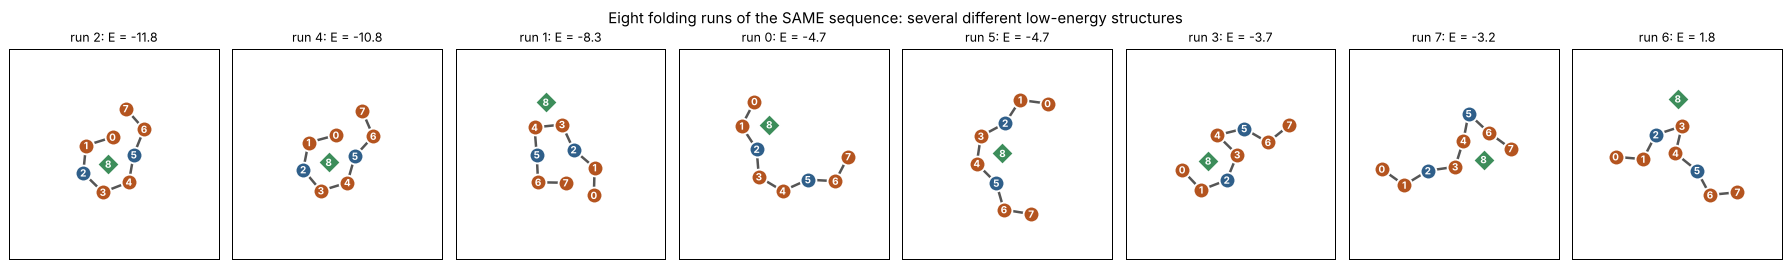

In [3]:
S = 12                                  # a test sequence we will follow through the notebook
types = test["types"][S]
labs = viz.token_labels(types)
print("sequence:", " ".join(labs))

fig, axes = plt.subplots(1, 8, figsize=(20, 3))
order = np.argsort(np.asarray(test["energy"][S]))
for ax, k in zip(axes, order):
    viz.draw_molecule(ax, test["x"][S, k], types, f"run {k}: E = {float(test['energy'][S, k]):.1f}", size=160)
fig.suptitle("Eight folding runs of the SAME sequence: several different low-energy structures")
plt.tight_layout(); plt.show()

**This is the point of the whole notebook.** One sequence, several valid structures: which H beads touch, where the
ligand sits. A model that must output *one* structure has to pick one or, trained with MSE, will output their
**average**, which is usually not a valid structure at all. A generative model can output *any* of them.

The energy terms of one structure, and of its mirror image (same distances, opposite handedness):

term        structure     mirror
bond            0.015      0.015
bend            2.134     20.975
repulsion       0.131      0.131
H-H            -4.138     -4.138
ligand         -9.936     -9.936
total         -11.793      7.048


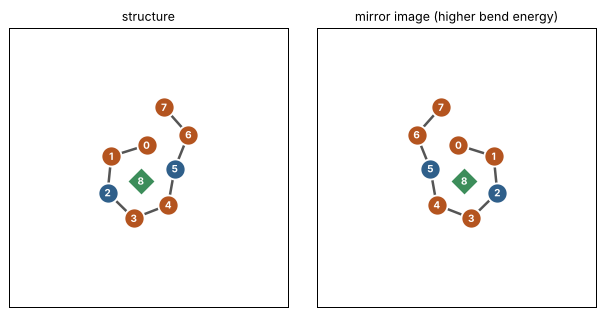

In [4]:
x_best = test["x"][S, order[0]]
terms = {k: float(v) for k, v in energy_terms(x_best, types).items()}
terms_m = {k: float(v) for k, v in energy_terms(mirror(x_best), types).items()}
print(f"{'term':10s} {'structure':>10s} {'mirror':>10s}")
for k in terms:
    print(f"{k:10s} {terms[k]:10.3f} {terms_m[k]:10.3f}")
print(f"{'total':10s} {sum(terms.values()):10.3f} {sum(terms_m.values()):10.3f}")

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
viz.draw_molecule(axes[0], x_best, types, "structure")
viz.draw_molecule(axes[1], mirror(x_best), types, "mirror image (higher bend energy)")
plt.tight_layout(); plt.show()

Only the **bend** term changes: every distance is identical, so a model that only looked at distances could not
tell these apart. Keep this in mind for Section 9.

## 2. From sequence to the single and pair representations

AF3 tokenizes the input (one token per residue or nucleotide, one per atom for ligands) and builds two
representations that the whole network carries:

* the **single** representation `s`, one vector per token, shape `(N, C_s) = (9, 16)`,
* the **pair** representation `z`, one vector per *pair* of tokens, shape `(N, N, C_z) = (9, 9, 8)`.

The input features here are a one-hot type `s_in` (H, P, L) and a one-hot **relative position** `relpos_ij =
clip(j − i, −4, 4)`, with a separate bin for any pair involving the ligand (it is not on the chain). AF3 uses the same
idea with residue index, chain id and entity id.

$$ s_i = W_s\, s^{in}_i, \qquad z_{ij} = W_a\, s^{in}_i + W_b\, s^{in}_j + W_r\, \mathrm{relpos}_{ij} $$

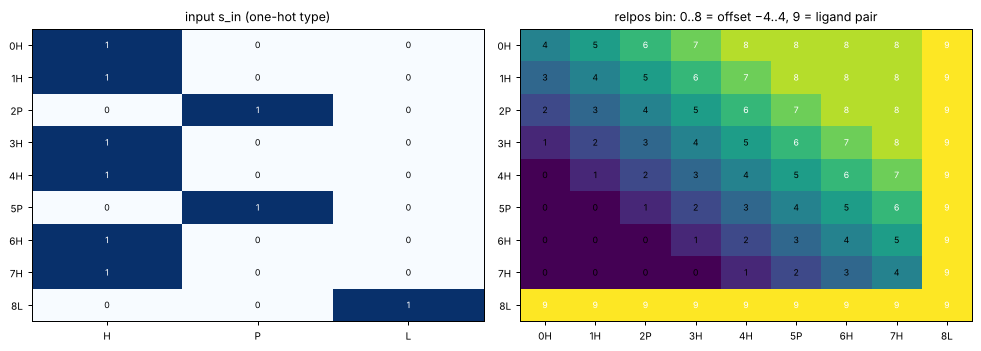

In [5]:
cfg = AF3Config()
params0 = init_params(jax.random.PRNGKey(1), cfg)
rel = relpos_features(9)
rel_bin = np.argmax(np.asarray(rel), -1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
viz.heatmap(axes[0], np.asarray(jax.nn.one_hot(types, 3)), labs, ["H", "P", "L"], "input s_in (one-hot type)", fmt="{:.0f}", cmap="Blues", vmax=1)
viz.heatmap(axes[1], rel_bin, labs, labs, "relpos bin: 0..8 = offset −4..4, 9 = ligand pair", fmt="{:.0f}", cmap="viridis", vmax=9)
plt.tight_layout(); plt.show()

### Worked example: one entry of the pair representation

Take the pair (bead 2, bead 5). Its channel vector is the sum of three rows: the row of `W_a` for bead 2's type, the
row of `W_b` for bead 5's type, and the row of `W_r` for relative position `+3` (bin 7). We compute it by hand and
check it against the code.

In [6]:
tr0 = apply_with_trace(params0, types, test["x"][S, 0], 1.0, cfg)
i, j = 2, 5
ti, tj = int(types[i]), int(types[j])
Wa, ba = params0["embed_zi"]; Wb, bb = params0["embed_zj"]; Wr, br = params0["embed_rel"]
by_hand = (Wa[ti] + ba) + (Wb[tj] + bb) + (Wr[rel_bin[i, j]] + br)
np.set_printoptions(precision=3, suppress=True)
print(f"type of {i} = {'HPL'[ti]}, type of {j} = {'HPL'[tj]}, relpos bin = {rel_bin[i, j]}")
print("W_a row    :", np.asarray(Wa[ti]))
print("W_b row    :", np.asarray(Wb[tj]))
print("W_r row    :", np.asarray(Wr[rel_bin[i, j]]))
print("sum        :", np.asarray(by_hand))
print("code z0[i,j]:", np.asarray(tr0["z0"][i, j]))

type of 2 = P, type of 5 = P, relpos bin = 7
W_a row    : [-0.119  0.621  0.263  1.412  0.761 -0.068  0.818  0.314]
W_b row    : [-0.806  0.79  -1.022 -0.579  0.294 -0.404  0.626 -0.542]
W_r row    : [ 0.124  0.133 -0.272 -0.16   0.006 -0.148  0.32  -0.354]
sum        : [-0.802  1.544 -1.031  0.673  1.061 -0.62   1.764 -0.582]
code z0[i,j]: [-0.802  1.544 -1.031  0.673  1.061 -0.62   1.764 -0.582]


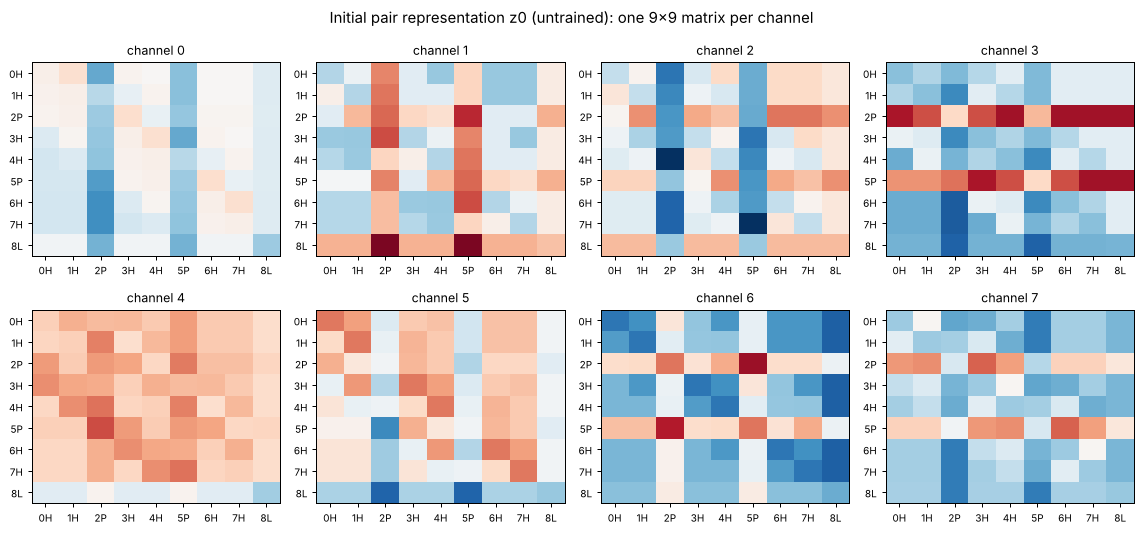

In [7]:
fig = viz.pair_channels(tr0["z0"], types, "Initial pair representation z0 (untrained): one 9×9 matrix per channel")
plt.show()

## 3. One Pairformer block, tensor by tensor

Each Pairformer block (AF3 Fig. 2a) updates the pair representation first and the single representation second:

```
z += TriangleMultiplication(outgoing)(z)
z += TriangleMultiplication(incoming)(z)
z += Transition(z)
s += AttentionWithPairBias(s, z)
s += Transition(s)
```

AF3 also has triangle *attention* (starting and ending node) in each block; this toy keeps only the multiplicative
updates, which carry the same idea more cheaply.

### Triangle multiplication: three tokens at a time

The pair `(i, j)` is updated using every third token `k`. With two gated projections `a = σ(·) ⊙ Linear(z)` and
`b = σ(·) ⊙ Linear(z)`,

$$ \text{outgoing:}\quad t_{ij} = \sum_k a_{ik} \odot b_{jk}, \qquad \text{incoming:}\quad t_{ij} = \sum_k a_{ki} \odot b_{kj}. $$

Why triangles? Distances in a real structure obey the triangle inequality: if `i` is close to `k` and `j` is close to
`k`, then `i` is close to `j`. The update lets the network enforce that kind of consistency. This is the part of
AF2's Evoformer that survives unchanged in AF3.

a[2,k,0] for k=0..8: [ 0.369 -0.124 -0.081  0.256 -0.062 -0.209  0.406  0.406  0.075]
b[5,k,0] for k=0..8: [-0.417 -0.417 -0.431 -0.326 -0.085 -0.115 -0.12  -0.075 -0.328]
products            : [-0.154  0.052  0.035 -0.083  0.005  0.024 -0.049 -0.031 -0.025]
t[2,5,0] = sum  = -0.2253
check with einsum    : -0.2253


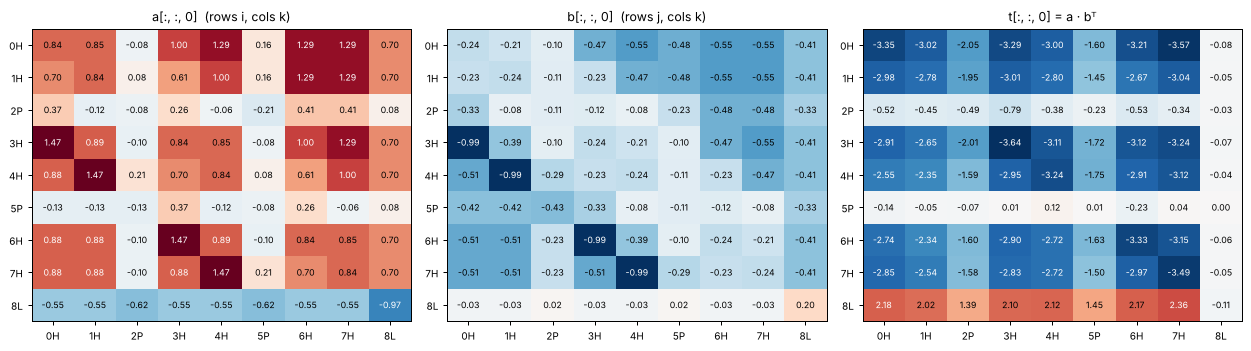

In [8]:
# Worked example: channel 0 of t_ij for the outgoing update, computed as an explicit sum over k
a = np.asarray(tr0["block0/tri_out/a"]); b = np.asarray(tr0["block0/tri_out/b"])
i, j, c = 2, 5, 0
terms_k = a[i, :, c] * b[j, :, c]
print(f"a[{i},k,{c}] for k=0..8:", a[i, :, c])
print(f"b[{j},k,{c}] for k=0..8:", b[j, :, c])
print("products            :", terms_k)
print(f"t[{i},{j},{c}] = sum  = {terms_k.sum():.4f}")
print("check with einsum    :", np.einsum("ikc,jkc->ijc", a, b)[i, j, c].round(4))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
viz.heatmap(axes[0], a[:, :, c], labs, labs, f"a[:, :, {c}]  (rows i, cols k)")
viz.heatmap(axes[1], b[:, :, c], labs, labs, f"b[:, :, {c}]  (rows j, cols k)")
viz.heatmap(axes[2], np.einsum("ikc,jkc->ijc", a, b)[:, :, c], labs, labs, f"t[:, :, {c}] = a · bᵀ")
plt.tight_layout(); plt.show()

For one channel, the outgoing update is just a **matrix product** `t = a · bᵀ`: row `i` of `a` dotted with row `j`
of `b`. The incoming one is `aᵀ · b`. That is why it costs `O(N³)`, the main expense of AF2 and AF3.

### Attention with pair bias: the pair representation steers the single one

The single representation is updated by ordinary multi-head self-attention, except that each head's logits get a
bias read from the pair representation:

$$ w^h_{ij} = \mathrm{softmax}_j\Big(\tfrac{q^h_i \cdot k^h_j}{\sqrt d} + \underbrace{\mathrm{Linear}(z_{ij})_h}_{\text{pair bias}}\Big) $$

This is how information flows from the pair track to the single track, the same mechanism the diffusion module
uses to read the trunk.

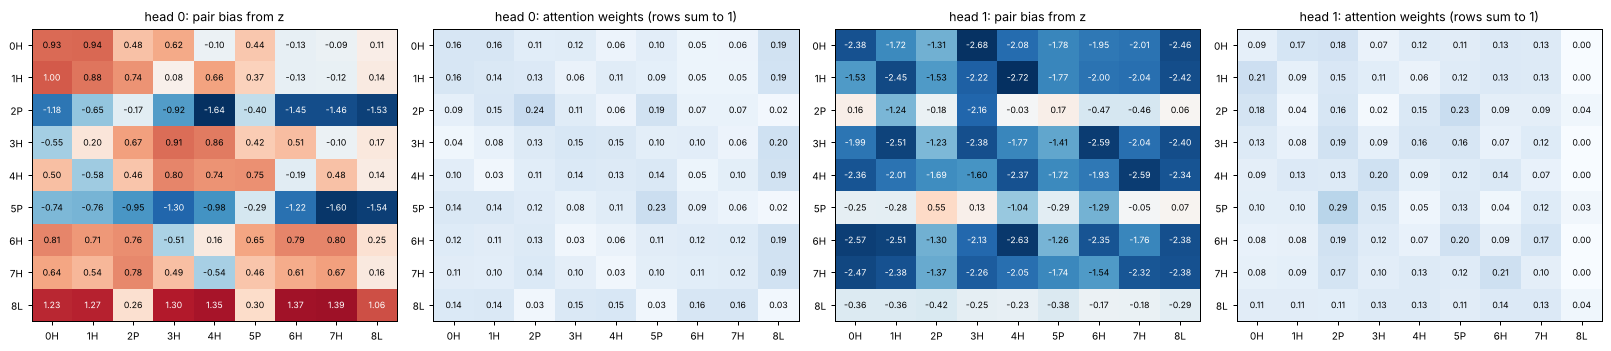

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for h in range(cfg.heads):
    viz.heatmap(axes[2 * h], tr0["block0/attn/pair_bias"][h], labs, labs, f"head {h}: pair bias from z")
    viz.heatmap(axes[2 * h + 1], tr0["block0/attn/weights"][h], labs, labs, f"head {h}: attention weights (rows sum to 1)", cmap="Blues", vmax=1)
plt.tight_layout(); plt.show()

## 4. The diffusion module: a denoiser on raw coordinates

This is AF3's real departure from AF2. The diffusion module gets **noisy coordinates** `x̃ = x + σ ε` and the noise
level `σ`, plus the trunk's `s` and `z`, and predicts the clean coordinates. AF3 states it "operates directly on raw
atom coordinates … without rotational frames or any equivariant processing". Rotations are handled by **data
augmentation** instead: every training structure is randomly rotated and translated.

It uses the EDM parameterization of Karras et al. (2022). The network output `r` is mixed with the input so that the
network always predicts something of unit scale:

$$ \hat x = c_{skip}(\sigma)\,\tilde x + c_{out}(\sigma)\, r\big(c_{in}(\sigma)\,\tilde x,\ c_{noise}(\sigma),\ s, z\big) $$

$$ c_{in} = \frac{1}{\sqrt{\sigma^2+\sigma_d^2}},\quad c_{skip} = \frac{\sigma_d^2}{\sigma^2+\sigma_d^2},\quad c_{out} = \frac{\sigma\sigma_d}{\sqrt{\sigma^2+\sigma_d^2}},\quad c_{noise} = \tfrac14\ln(\sigma/\sigma_d) $$

At **small** σ, `c_skip ≈ 1`: the input is almost right and the network only adds a small correction (local
chemistry: bond lengths, turns). At **large** σ, `c_skip ≈ 0`: the input is nearly pure noise and the network must
produce the structure from the conditioning alone (global arrangement: which H's touch, where the ligand goes).

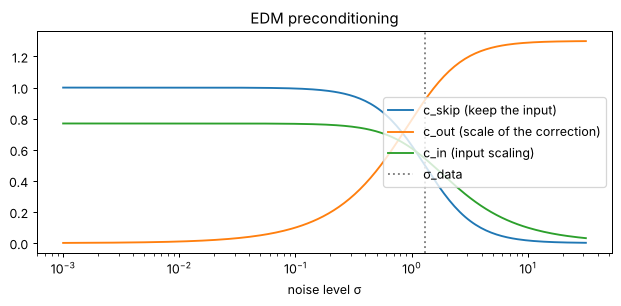

In [10]:
sig = np.logspace(-3, 1.5, 200)
cin, cskip, cout, cnoise = [np.asarray(v) for v in precond(jnp.asarray(sig), cfg.sigma_data)]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogx(sig, cskip, label="c_skip (keep the input)")
ax.semilogx(sig, cout, label="c_out (scale of the correction)")
ax.semilogx(sig, cin, label="c_in (input scaling)")
ax.axvline(cfg.sigma_data, color="grey", ls=":", label="σ_data")
ax.set_xlabel("noise level σ"); ax.legend(); ax.set_title("EDM preconditioning")
plt.tight_layout(); plt.show()

## 5. Train it (and an AF2-style baseline), keeping snapshots

**AF3-style model:** for each training structure we run the trunk **once** and the diffusion module at 8 noise
levels (AF3 uses 48, the "diffusion batch", because the trunk is expensive and the denoiser is cheap). Noise levels
are drawn as `σ = σ_d · exp(−1.2 + 1.5 n)`, and the loss is the EDM-weighted MSE after rigidly aligning the target
onto the prediction.

**AF2-style baseline:** the same trunk, but a deterministic head `x = Linear(LayerNorm(s))`, trained with
alignment-invariant MSE against a random one of the 8 runs of its sequence. This is the "learn a map" approach.

About 2–3 minutes on a laptop CPU.

diffusion step   250  loss 1.2012  (18s)


diffusion step   500  loss 0.7979  (30s)


diffusion step   750  loss 0.7350  (40s)


diffusion step  1000  loss 0.6981  (52s)


diffusion step  1250  loss 0.6807  (63s)


diffusion step  1500  loss 0.6610  (74s)


... (14 outputs left out)

regression step  2250  loss 0.8208  (37s)


regression step  2500  loss 0.8125  (41s)


regression step  2750  loss 0.8176  (44s)


regression step  3000  loss 0.8122  (47s)


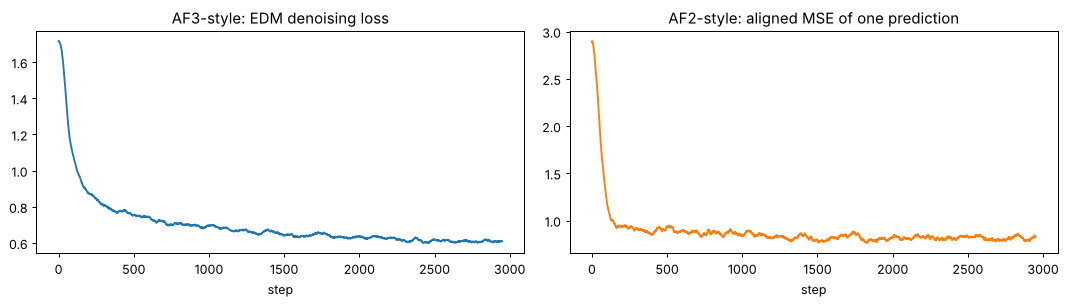

In [11]:
params_af3, hist_af3 = train(params0, data, cfg, mode="diffusion", steps=3000, snapshot_every=250)
params_reg, hist_reg = train(params0, data, cfg, mode="regression", steps=3000, snapshot_every=250)

def smooth(v, k=50):
    return np.convolve(v, np.ones(k) / k, mode="valid")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(smooth(hist_af3["loss"])); axes[0].set_title("AF3-style: EDM denoising loss"); axes[0].set_xlabel("step")
axes[1].plot(smooth(hist_reg["loss"]), color="C1"); axes[1].set_title("AF2-style: aligned MSE of one prediction"); axes[1].set_xlabel("step")
plt.tight_layout(); plt.show()

The two losses are not comparable numbers. Notice what the regression loss does, though: it stops falling at a
plateau. That plateau is the irreducible spread between the different valid structures of a sequence: no single
answer can be close to all of them.

## 6. Sampling: watching noise become a molecule

AF3's sampler (Supplementary Algorithm 18) starts from noise at `σ_max = 10 σ_d` and walks down a schedule
`σ_i = σ_d (s_max^{1/7} + t_i (s_min^{1/7} − s_max^{1/7}))^7`. Each step: randomly rotate the current sample, add a
little fresh noise (`γ₀ = 0.8` while σ > 1), call the denoiser, and take an Euler step towards its guess, scaled by
`η = 1.5`. The trunk is computed **once**; only the cheap denoiser runs 40 times (AF3: 200).

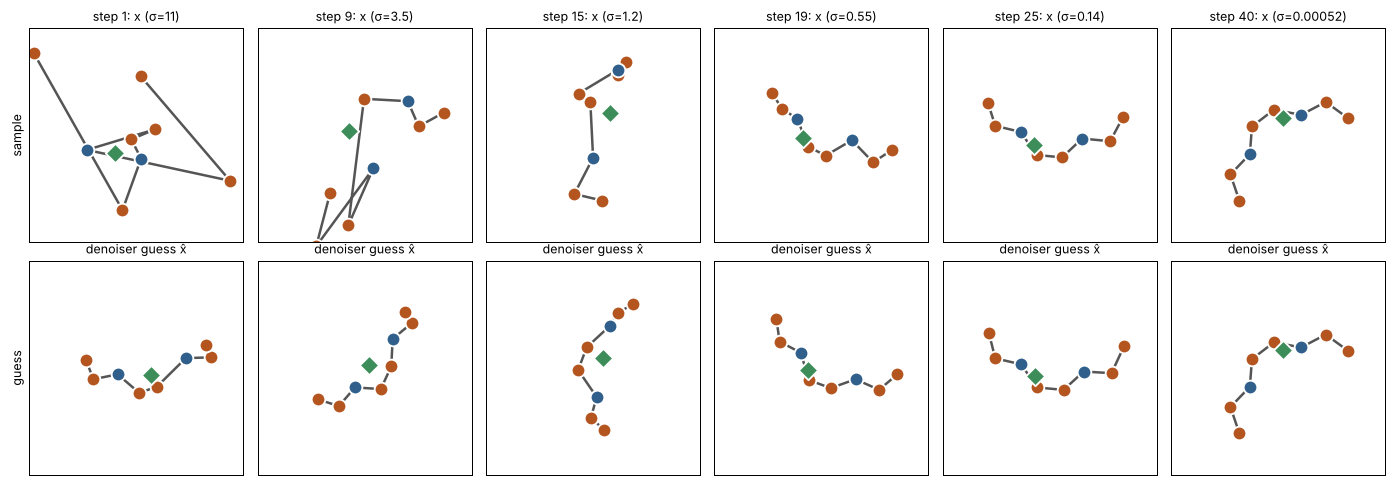

In [12]:
x_final, path, dens, sigmas = sample(params_af3, types, jax.random.PRNGKey(7), cfg, n_steps=40, return_path=True)
fig = viz.denoising_strip(np.asarray(path), np.asarray(dens), np.asarray(sigmas), types)
plt.show()

Read the bottom row: at high noise the denoiser's guess is a compact, blurry average (it cannot know yet which fold
this will be). As σ falls, the sample commits to one arrangement and the guess sharpens into a chain with unit bonds.

Now 8 independent samples for the same test sequence, next to the 8 true folding runs and the regression baseline's
single answer:

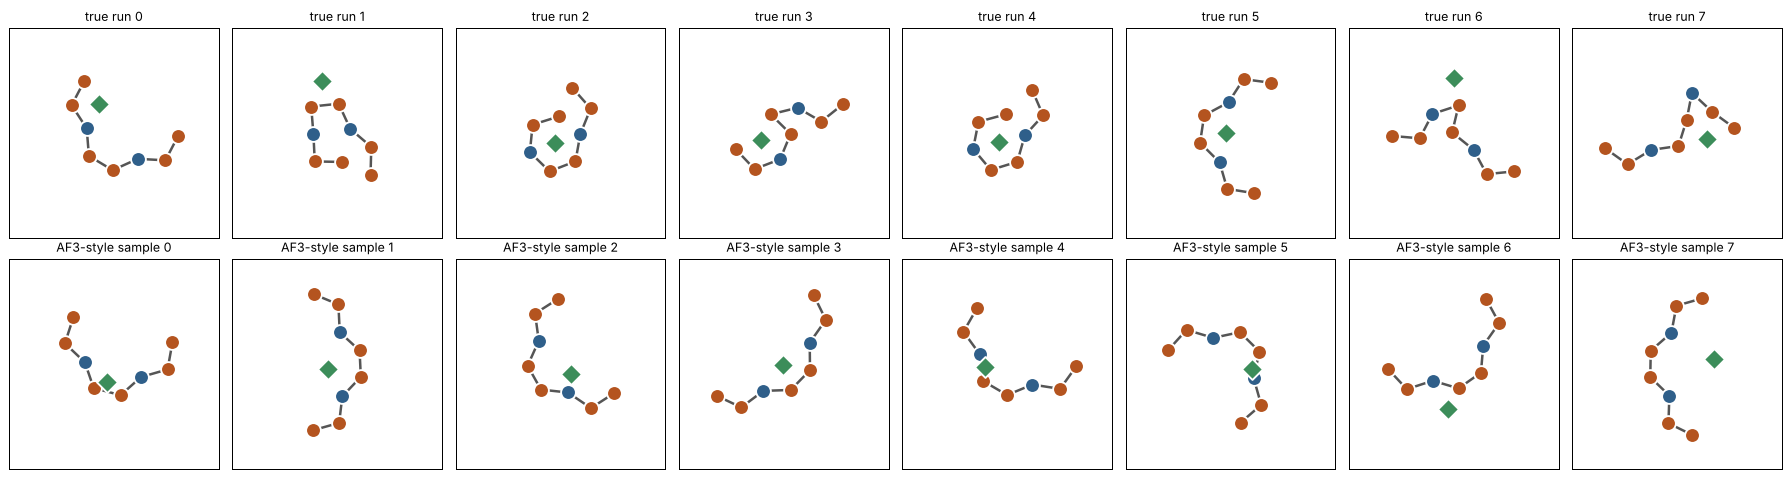

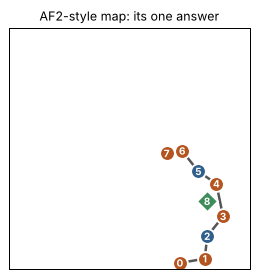

In [13]:
samples = sample_many(params_af3, types, jax.random.PRNGKey(11), 8, cfg)
x_reg = apply_regression(params_reg, types, cfg)

fig, axes = plt.subplots(2, 8, figsize=(20, 5.4))
for k in range(8):
    viz.draw_molecule(axes[0, k], test["x"][S, k], types, f"true run {k}", size=140, labels=False)
    viz.draw_molecule(axes[1, k], samples[k], types, f"AF3-style sample {k}", size=140, labels=False)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(3.2, 3.2))
viz.draw_molecule(ax, x_reg, types, "AF2-style map: its one answer", size=140)
plt.tight_layout(); plt.show()

## 7. Interactive explorer: inside the network at any point of training

Sliders:

* **training step**: which weight snapshot (every 250 steps),
* **test sequence**: which of the 40 unseen sequences,
* **sampling step**: how far along the 40-step denoising path.

The figure shows the current sample and the denoiser's guess, the pair representation (channel 0) after the last
Pairformer block, and head 0's attention weights in the last diffusion layer. Press **Run Interact** to redraw
(drawing many panels on every slider move is slow).

In [14]:
import ipywidgets as w

snap_steps = [s for s, _ in hist_af3["snapshots"]]
snap = dict(hist_af3["snapshots"])
_paths = {}

def get_path(step, seq):
    if (step, seq) not in _paths:
        _paths[(step, seq)] = sample(snap[step], test["types"][seq], jax.random.PRNGKey(seq), cfg, return_path=True)
    return _paths[(step, seq)]

def explore(train_step=snap_steps[-1], seq=S, sample_step=39):
    ty = test["types"][seq]
    lb = viz.token_labels(ty)
    x, pth, dns, sg = get_path(train_step, seq)
    tr = apply_with_trace(snap[train_step], ty, pth[sample_step], float(sg[sample_step + 1]), cfg)
    fig, axes = plt.subplots(1, 4, figsize=(19, 4.3))
    xs_now = np.asarray(pth[sample_step])
    lim = max(3.8, float(np.abs(xs_now - xs_now.mean(0)).max()) + 0.5)
    viz.draw_molecule(axes[0], xs_now - xs_now.mean(0), ty, f"sample after step {sample_step + 1} (σ={float(sg[sample_step + 1]):.2g})", lim=lim)
    guess = np.asarray(dns[sample_step]); guess = guess - guess.mean(0)
    near = int(np.argmin([float(rmsd(t, guess)) for t in test["x"][seq]]))
    viz.draw_molecule(axes[1], guess, ty, f"denoiser guess x̂ (grey: nearest true run {near})", ghost=align(test["x"][seq, near], guess))
    viz.heatmap(axes[2], tr[f"block{cfg.blocks - 1}/z"][:, :, 0], lb, lb, "pair z, channel 0 (last block)", annotate=False)
    viz.heatmap(axes[3], tr[f"diff{cfg.diff_layers - 1}/attn/weights"][0], lb, lb, "diffusion attention, head 0", cmap="Blues", vmax=1, annotate=False)
    fig.suptitle(f"training step {train_step}, test sequence {seq}: " + " ".join(lb))
    plt.tight_layout(); plt.show()

w.interact_manual(explore,
                  train_step=w.SelectionSlider(options=snap_steps, value=snap_steps[-1], description="training step"),
                  seq=w.IntSlider(value=S, min=0, max=39, description="test seq"),
                  sample_step=w.IntSlider(value=39, min=0, max=39, description="sampling step"));

interactive(children=(SelectionSlider(description='training step', index=12, options=(0, 250, 500, 750, 1000, …

### Static version: the same test sequence at three points in training

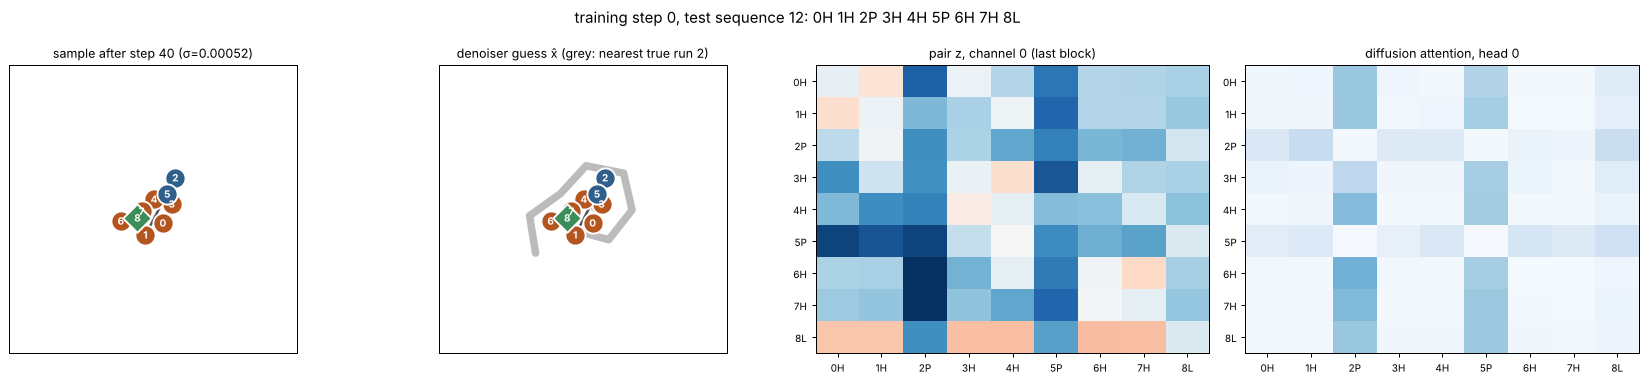

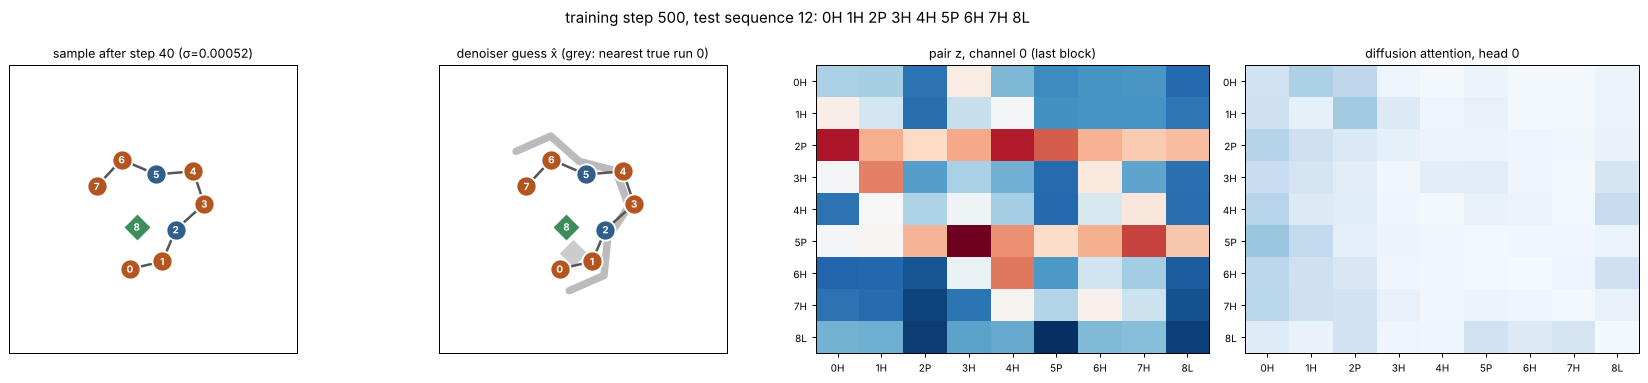

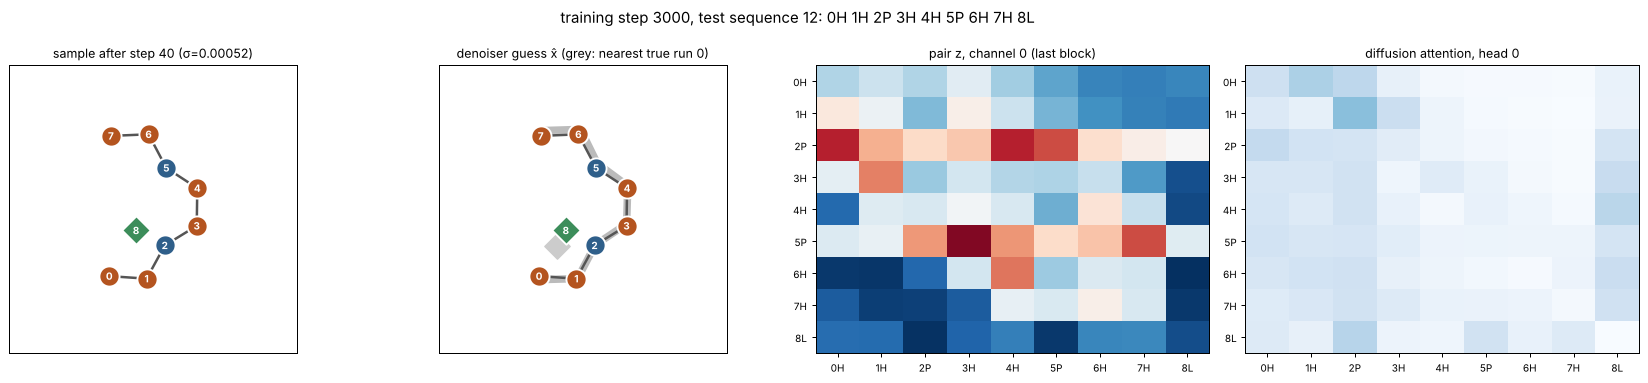

In [15]:
for st in [snap_steps[0], snap_steps[2], snap_steps[-1]]:
    explore(st, S, 39)

At step 0 the denoiser is random and the "sample" is noise. After a few hundred steps it already makes compact
blobs; by the end, chains with unit bonds and the ligand docked against H beads.

## 8. Map vs denoiser, measured against the physics

We know the true energy, so we can grade predictions physically, on all 40 unseen sequences:

* **energy** `E(x)` (true runs are around −3; lower is more physical),
* **bond error**: mean |bond length − 1|,
* **precision**: RMSD from each prediction to the nearest true run (is each prediction *a* valid structure?),
* **coverage**: RMSD from each true run to the nearest prediction (are *all* the valid structures found?).

In [16]:
rm = jax.jit(jax.vmap(jax.vmap(rmsd, (None, 0)), (0, None)))
E_v = jax.jit(jax.vmap(energy, (0, None)))

def grade(xs, ty, xt):
    r = rm(xs, xt)
    return dict(energy=float(jnp.median(E_v(xs, ty))), bond_err=float(jax.vmap(bond_error)(xs).mean()),
                precision=float(r.min(1).mean()), coverage=float(r.min(0).mean()))

rows = {"true runs (each vs the other 7)": [], "AF3-style (8 samples)": [], "AF2-style map (1 answer)": []}
all_samples = []
for s in range(40):
    ty, xt = test["types"][s], test["x"][s]
    xs = sample_many(params_af3, ty, jax.random.PRNGKey(100 + s), 8, cfg)
    all_samples.append(xs)
    r = np.asarray(rm(xt, xt)) + np.diag(np.full(8, np.inf))    # each run vs the 7 others
    rows["true runs (each vs the other 7)"].append(dict(
        energy=float(jnp.median(test["energy"][s])), bond_err=float(jax.vmap(bond_error)(xt).mean()),
        precision=float(r.min(1).mean()), coverage=float(r.min(0).mean())))
    rows["AF3-style (8 samples)"].append(grade(xs, ty, xt))
    rows["AF2-style map (1 answer)"].append(grade(apply_regression(params_reg, ty, cfg)[None], ty, xt))

print(f"{'':32s} {'energy':>8s} {'bond err':>9s} {'precision':>10s} {'coverage':>9s}")
for name, rs in rows.items():
    m = {k: np.mean([r[k] for r in rs]) for k in rs[0]}
    print(f"{name:32s} {m['energy']:8.2f} {m['bond_err']:9.3f} {m['precision']:10.3f} {m['coverage']:9.3f}")

                                   energy  bond err  precision  coverage
true runs (each vs the other 7)     -3.54     0.002      0.583     0.583
AF3-style (8 samples)               12.41     0.018      0.441     0.685
AF2-style map (1 answer)            49.30     0.151      0.439     0.858


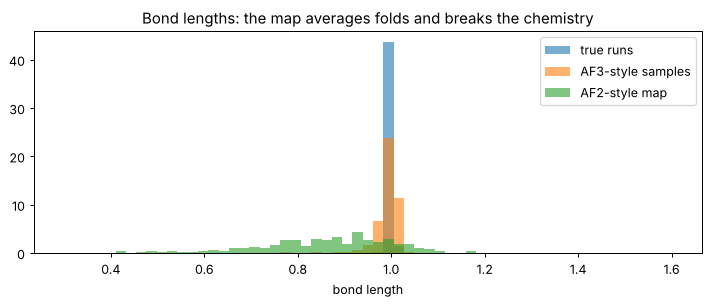

In [17]:
def bonds(xs):
    xs = np.asarray(xs)[..., :-1, :]
    return np.linalg.norm(xs[..., 1:, :] - xs[..., :-1, :], axis=-1).ravel()

reg_all = np.stack([np.asarray(apply_regression(params_reg, test["types"][s], cfg)) for s in range(40)])
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(0.3, 1.6, 60)
ax.hist(bonds(test["x"]), bins, alpha=0.6, density=True, label="true runs")
ax.hist(bonds(np.stack(all_samples)), bins, alpha=0.6, density=True, label="AF3-style samples")
ax.hist(bonds(reg_all), bins, alpha=0.6, density=True, label="AF2-style map")
ax.set_xlabel("bond length"); ax.legend(); ax.set_title("Bond lengths: the map averages folds and breaks the chemistry")
plt.tight_layout(); plt.show()

**Reading the table.** The regression map can have a reasonable *precision* (its average structure is not far from
any of them), but its bonds are wrong and its energy is far above the true structures: the average of two valid
folds is not a valid fold. AF2 avoided this with a hand-built head (rigid frames with fixed bond geometry, torsion
angles, violation losses). AF3 avoids it by changing *what is learned*: the denoiser is trained at every noise
level, so at small σ it learns local chemistry (bond lengths come out right with no bond loss at all), and sampling
picks **one** mode instead of averaging. The coverage column shows the samples spread over the valid structures
roughly as much as independent folding runs do.

The samples' energy is still higher than the true runs': a small model trained for 3 minutes leaves small clashes
and bend errors. AF3 has the same issue at a much smaller scale, and its follow-ups (e.g. Boltz-1x, Boltz-2) add
physics potentials at sampling time ("steering") to clean them up.

## 9. Chirality: can a non-equivariant model get the handedness right?

The denoiser never sees a mirrored structure (augmentation only rotates and translates), so handedness must be
learned from the data. We count samples whose mirror image fits the preferred turns better than the sample itself,
across the training snapshots.

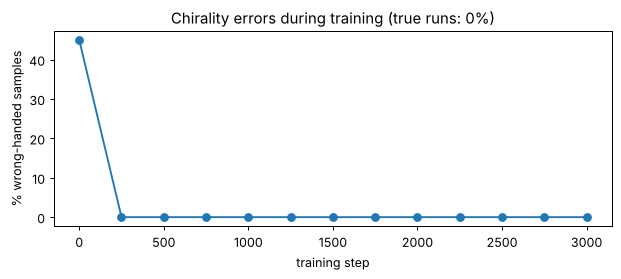

final: 0.0% wrong-handed


In [18]:
wh_v = jax.jit(jax.vmap(wrong_handed, (0, None)))
fr = []
for st in snap_steps:
    bad = []
    for s in range(20):
        xs = sample_many(snap[st], test["types"][s], jax.random.PRNGKey(200 + s), 8, cfg)
        bad.append(np.asarray(wh_v(xs, test["types"][s])))
    fr.append(np.mean(bad))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(snap_steps, np.array(fr) * 100, "o-")
ax.set_xlabel("training step"); ax.set_ylabel("% wrong-handed samples")
ax.set_title("Chirality errors during training (true runs: 0%)")
plt.tight_layout(); plt.show()
print("final: %.1f%% wrong-handed" % (100 * fr[-1]))

In this 2D toy, the handedness is easy to learn: the signed-turn preference is felt by every bead, so the error rate
falls quickly. In real molecules chirality lives at a few stereocentres of a ligand, a tiny part of a large complex,
and AF3 still gets it wrong 4.4% of the time on PoseBusters. Equivariant architectures (like AF2's frames) would
build in rotations but also have to be designed carefully not to build in reflections; AF3's choice was to drop the
machinery and learn it all from data.

## Takeaways, connected to the paper

* **Two parents.** The trunk (pair representation, triangle updates, attention with pair bias) is AF2's Evoformer,
  slimmed into the Pairformer. The head is a diffusion model in the EDM form (Karras et al., 2022).
* **What is learned changes.** AF2 learns a map to one structure; AF3 learns a denoiser, i.e. the score of
  `p(structure | sequence)`. Section 8 shows why that matters even in a toy: a map averages valid structures into an
  invalid one.
* **Chemistry from data, not from losses.** No bond loss, no frames, no torsions: small-σ denoising teaches bond
  lengths and turns. This is what lets AF3 take any molecule, since nothing in the head is protein-specific.
* **Generative failure modes.** Sampling can produce plausible structure where there is none (AF3's hallucination
  in disordered regions, fixed with cross-distillation from AF-Multimer), and chirality or clashes are not
  guaranteed (Section 9).
* **Left out here:** the MSA module, triangle attention, templates, the atom-level transformers, and the confidence
  head (pLDDT, PAE, PDE), which AF3 trains with a quick "mini-rollout" of the sampler.